# Los Angeles Crime Data - InfluxDB Homework
## Sistemi Informativi Evoluti e Big Data - A.A. 2025-2026

Questo notebook implementa l'analisi completa del dataset [Crime Data from 2020 to Present](https://catalog.data.gov/dataset/crime-data-from-2020-to-present) utilizzando InfluxDB.

## Setup - Installazione delle librerie necessarie

In [1]:
# Importazione librerie
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from influxdb_client import InfluxDBClient, Point, WriteOptions
from influxdb_client.client.write_api import SYNCHRONOUS
from datetime import datetime
import warnings

warnings.filterwarnings('ignore')

## 1. Configurazione e Caricamento Dati

Configuriamo la connessione a InfluxDB e carichiamo il dataset CSV.

In [2]:
# Configurazione InfluxDB
url = "http://localhost:8086"
token = "W3cPRGkq7ds7JHFNtuciiVqEVPGugFye82mykiLWWee2FMxLDflsqsHk8OJaavTS9Sjh1_H31xU4yh3J5IC9RA=="
org = "unibs"
bucket = "crime_data"

client = InfluxDBClient(url=url, token=token, org=org)
write_api = client.write_api(write_options=SYNCHRONOUS)
query_api = client.query_api()

In [1]:
import pandas as pd

# Imposta pandas per mostrare tutte le colonne
pd.set_option('display.max_columns', None)

# (Opzionale) Se hai stringhe molto lunghe che vengono tagliate
pd.set_option('display.max_colwidth', None)

In [2]:
csv_path = "Crime_Data_from_2020_to_Present.csv"
df = pd.read_csv(csv_path)
df.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,Mocodes,Vict Age,Vict Sex,Vict Descent,Premis Cd,Premis Desc,Weapon Used Cd,Weapon Desc,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,211507896,04/11/2021 12:00:00 AM,11/07/2020 12:00:00 AM,845,15,N Hollywood,1502,2,354,THEFT OF IDENTITY,0377,31,M,H,501.0,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,354.0,NaN,NaN,NaN,7800 BEEMAN AV,NaN,34.2124,-118.4092
1,201516622,10/21/2020 12:00:00 AM,10/18/2020 12:00:00 AM,1845,15,N Hollywood,1521,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",0416 0334 2004 1822 1414 0305 0319 0400,32,M,H,102.0,SIDEWALK,200.0,KNIFE WITH BLADE 6INCHES OR LESS,IC,Invest Cont,230.0,NaN,NaN,NaN,ATOLL AV,N GAULT,34.1993,-118.4203
2,240913563,12/10/2024 12:00:00 AM,10/30/2020 12:00:00 AM,1240,9,Van Nuys,933,2,354,THEFT OF IDENTITY,0377,30,M,W,501.0,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,354.0,NaN,NaN,NaN,14600 SYLVAN ST,NaN,34.1847,-118.4509
3,210704711,12/24/2020 12:00:00 AM,12/24/2020 12:00:00 AM,1310,7,Wilshire,782,1,331,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND OVER),0344,47,F,A,101.0,STREET,NaN,NaN,IC,Invest Cont,331.0,NaN,NaN,NaN,6000 COMEY AV,NaN,34.0339,-118.3747
4,201418201,10/03/2020 12:00:00 AM,09/29/2020 12:00:00 AM,1830,14,Pacific,1454,1,420,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),1300 0344 1606 2032,63,M,H,103.0,ALLEY,NaN,NaN,IC,Invest Cont,420.0,NaN,NaN,NaN,4700 LA VILLA MARINA,NaN,33.9813,-118.4350


In [5]:
print(f"Dimensioni: {df.shape}")

Dimensioni: (1004991, 28)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004991 entries, 0 to 1004990
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004991 non-null  int64  
 1   Date Rptd       1004991 non-null  object 
 2   DATE OCC        1004991 non-null  object 
 3   TIME OCC        1004991 non-null  int64  
 4   AREA            1004991 non-null  int64  
 5   AREA NAME       1004991 non-null  object 
 6   Rpt Dist No     1004991 non-null  int64  
 7   Part 1-2        1004991 non-null  int64  
 8   Crm Cd          1004991 non-null  int64  
 9   Crm Cd Desc     1004991 non-null  object 
 10  Mocodes         853372 non-null   object 
 11  Vict Age        1004991 non-null  int64  
 12  Vict Sex        860347 non-null   object 
 13  Vict Descent    860335 non-null   object 
 14  Premis Cd       1004975 non-null  float64
 15  Premis Desc     1004403 non-null  object 
 16  Weapon Used Cd  327247 non-null   fl

In [7]:
df.describe()

,DR_NO,TIME OCC,AREA,Rpt Dist No,Part 1-2,Crm Cd,Vict Age,Premis Cd,Weapon Used Cd,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LAT,LON
count,1.004991e+06,1.004991e+06,1.004991e+06,1.004991e+06,1.004991e+06,1.004991e+06,1.004991e+06,1.004975e+06,327247.000000,1.004980e+06,69160.000000,2314.000000,64.00000,1.004991e+06,1.004991e+06
mean,2.202215e+08,1.339900e+03,1.069174e+01,1.115633e+03,1.400348e+00,5.001568e+02,2.891706e+01,3.056201e+02,363.955300,4.999174e+02,958.101258,984.015990,991.21875,3.399821e+01,-1.180909e+02
std,1.319718e+07,6.510613e+02,6.110255e+00,6.111605e+02,4.899691e-01,2.052731e+02,2.199272e+01,2.193021e+02,123.734528,2.050736e+02,110.354348,52.350982,27.06985,1.610713e+00,5.582386e+00
min,8.170000e+02,1.000000e+00,1.000000e+00,1.010000e+02,1.000000e+00,1.100000e+02,-4.000000e+00,1.010000e+02,101.000000,1.100000e+02,210.000000,310.000000,821.00000,0.000000e+00,-1.186676e+02
25%,2.106169e+08,9.000000e+02,5.000000e+00,5.870000e+02,1.000000e+00,3.310000e+02,0.000000e+00,1.010000e+02,311.000000,3.310000e+02,998.000000,998.000000,998.00000,3.401470e+01,-1.184305e+02
50%,2.209159e+08,1.420000e+03,1.100000e+01,1.139000e+03,1.000000e+00,4.420000e+02,3.000000e+01,2.030000e+02,400.000000,4.420000e+02,998.000000,998.000000,998.00000,3.405890e+01,-1.183225e+02
75%,2.311103e+08,1.900000e+03,1.600000e+01,1.613000e+03,2.000000e+00,6.260000e+02,4.400000e+01,5.010000e+02,400.000000,6.260000e+02,998.000000,998.000000,998.00000,3.416490e+01,-1.182739e+02
max,2.521041e+08,2.359000e+03,2.100000e+01,2.199000e+03,2.000000e+00,9.560000e+02,1.200000e+02,9.760000e+02,516.000000,9.560000e+02,999.000000,999.000000,999.00000,3.433430e+01,0.000000e+00


In [4]:
pd.set_option('display.max_rows', None)
print(df['Vict Descent'].value_counts().sort_index())

Vict Descent
-         2
A     21340
B    135816
C      4631
D        91
F      4838
G        74
H    296404
I      1015
J      1586
K      5990
L        77
O     78005
P       288
S        58
U       221
V      1195
W    201442
X    106685
Z       577
Name: count, dtype: int64


In [ ]:
# Filtriamo solo i record con età 0
df_zero = df[df['Vict Sex'] == 'H']

print("--- Analisi vittime con Età 0 ---")
print(f"Totale casi: {len(df_zero)}")

# 1. Controlliamo il sesso della vittima
# Se è prevalentemente 'X' (Sconosciuto) o NaN, allora età 0 = Dato Mancante
print("\nDistribuzione Sesso per Età 0:")
print(df_zero['Vict Sex'].value_counts(dropna=False).head())

# 2. Controlliamo il tipo di crimine
# Se i reati sono "Furto d'auto" o "Furto d'identità", la vittima non è una persona fisica, quindi età 0 è corretto (N/A).
print("\nTop 10 Crimini con vittime di Età 0:")
print(df_zero['Crm Cd Desc'].value_counts().head(10))

# 3. Cerchiamo i VERI neonati (0-1 anni)
# Cerchiamo crimini specifici contro l'infanzia (es. "CHILD ABUSE") che hanno età 0
child_crimes = df_zero[df_zero['Crm Cd Desc'].str.contains("CHILD", case=False, na=False)]
print(f"\nPossibili veri neonati (Crimini 'CHILD'): {len(child_crimes)}")

--- Analisi vittime con Età 0 ---
Totale casi: 1

Distribuzione Sesso per Età 0:
Vict Sex
-    1
Name: count, dtype: int64

Top 10 Crimini con vittime di Età 0:
Crm Cd Desc
VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)    1
Name: count, dtype: int64

Possibili veri neonati (Crimini 'CHILD'): 0


In [7]:
df.describe(include=['object'])

,Date Rptd,DATE OCC,AREA NAME,Crm Cd Desc,Mocodes,Vict Sex,Vict Descent,Premis Desc,Weapon Desc,Status,Status Desc,LOCATION,Cross Street
count,1004991,1004991,1004991,1004991,853372,860347,860335,1004403,327247,1004990,1004991,1004991,154236
unique,1896,1879,21,140,310940,5,20,306,79,6,6,66566,10413
top,02/02/2023 12:00:00 AM,01/01/2020 12:00:00 AM,Central,VEHICLE - STOLEN,0344,M,H,STREET,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,800 N ALAMEDA ST,BROADWAY
freq,929,1164,69670,115190,42187,403879,296404,261284,174761,802862,802862,2598,2486


In [8]:
print(df.isnull().sum())

DR_NO                   0
Date Rptd               0
DATE OCC                0
TIME OCC                0
AREA                    0
AREA NAME               0
Rpt Dist No             0
Part 1-2                0
Crm Cd                  0
Crm Cd Desc             0
Mocodes            151619
Vict Age                0
Vict Sex           144644
Vict Descent       144656
Premis Cd              16
Premis Desc           588
Weapon Used Cd     677744
Weapon Desc        677744
Status                  1
Status Desc             0
Crm Cd 1               11
Crm Cd 2           935831
Crm Cd 3          1002677
Crm Cd 4          1004927
LOCATION                0
Cross Street       850755
LAT                     0
LON                     0
dtype: int64


In [9]:
# Quante righe hanno coordinate 0?
zero_coords = df[(df['LAT'] == 0) | (df['LON'] == 0)]
print(f"Record con coordinate a 0: {len(zero_coords)}")

Record con coordinate a 0: 2240


In [ ]:
# --- Cella 7: Caricamento Dati Completo e Ottimizzato ---

print("--- Inizio procedura di caricamento su InfluxDB ---")

# 1. Definizione Soglie Alert (Simulazione basata sullo storico)
# Calcoliamo il massimo storico di crimini giornalieri per avere un riferimento
daily_counts = df['DATE OCC'].dt.date.value_counts()
MAX_CRIMES_DAY = daily_counts.max()
# Impostiamo soglie arbitrarie per la simulazione (es. 5% e 10% del picco storico)
SOGLIA_WARNING = MAX_CRIMES_DAY * 0.05 
SOGLIA_ALARM = MAX_CRIMES_DAY * 0.10

print(f"Soglie Alert Configurate: Warning > {SOGLIA_WARNING:.0f}, Alarm > {SOGLIA_ALARM:.0f} crimini/giorno")

# 2. Funzioni di Supporto per Feature Engineering
def get_season(date):
    if pd.isna(date): return "Unknown"
    month = date.month
    if month in [3, 4, 5]: return "Spring"
    elif month in [6, 7, 8]: return "Summer"
    elif month in [9, 10, 11]: return "Autumn"
    else: return "Winter"

def get_day_night(time_occ):
    if pd.isna(time_occ): return "Unknown"
    try:
        hour = int(time_occ / 100)
        return "Day" if 6 <= hour < 18 else "Night"
    except:
        return "Unknown"

# 3. Generatore Streaming (Core del Caricamento)
# Elabora il dataframe riga per riga simulando un flusso di dati
def data_generator(df_input):
    cutoff_date = pd.Timestamp('2025-11-30')
    excluded_count = 0
    valid_count = 0
    
    # Per la simulazione alert, teniamo un contatore giornaliero (semplificato)
    # In un vero stream useremmo una finestra temporale mobile.
    current_day_count = 0
    last_date = None

    for index, row in df_input.iterrows():
        
        # --- A. CONTROLLI DI ESCLUSIONE (Filtri di Validità) ---
        # "I valori fuori scala vanno esclusi dal caricamento"
        
        # 1. Coordinate Nulle (Trovati ~2000 casi nell'analisi)
        if row['Lat'] == 0 or row['Lon'] == 0:
            excluded_count += 1
            continue
            
        # 2. Date Future o Nulle
        if pd.isna(row['DATE OCC']) or row['DATE OCC'] > cutoff_date:
            excluded_count += 1
            continue
            
        # 3. Tipo di Crimine non valido
        if pd.isna(row['Crm_Cd']):
            excluded_count += 1
            continue

        # --- B. FEATURE ENGINEERING & PULIZIA ---
        
        season = get_season(row['DATE OCC'])
        day_night = get_day_night(row['TIME OCC'])
        
        # Gestione Attributi Vittima (Tag)
        # Se il dato manca (NaN o 'X'), usiamo "Unknown" per mantenere il tag
        vict_sex = str(row['Vict Sex']) if pd.notna(row['Vict Sex']) and row['Vict Sex'] != 'X' else "Unknown"
        vict_descent = str(row['Vict Descent']) if pd.notna(row['Vict Descent']) and row['Vict Descent'] != '-' else "Unknown"
        
        # Gestione Classificazione (Tag)
        part_1_2 = str(int(row['Part_1_2'])) if pd.notna(row['Part_1_2']) else "Unknown"

        # Gestione Arma (Tag Multipli)
        # Salviamo sia il dettaglio che il flag True/False
        
        # Logica Standard (Codice presente = Arma presente)
        if pd.notna(row['Weapon Used Cd']):
            weapon_flag = "True"
            # Usiamo la descrizione se c'è (pulita), altrimenti il codice
            weapon_detail = str(row['Weapon Desc']).strip() if pd.notna(row['Weapon Desc']) else str(row['Weapon Used Cd'])
            
            # --- LOGICA AVANZATA (Commentata per dimostrazione analisi) ---
            # Dall'analisi dati è emerso che 'STRONG-ARM' e 'VERBAL THREAT' sono classificati come armi.
            # Se volessimo distinguere le armi vere dalla violenza fisica, useremmo questo:
            # if "STRONG-ARM" in weapon_detail.upper() or "VERBAL THREAT" in weapon_detail.upper():
            #     weapon_flag = "False"  # Tecnicamente "Senza Arma Esterna"
            # -------------------------------------------------------------
            
        else:
            weapon_flag = "False"
            weapon_detail = "None"

        # --- C. SIMULAZIONE ALERT ---
        # Simuliamo il conteggio giornaliero
        if last_date != row['DATE OCC'].date():
            current_day_count = 0
            last_date = row['DATE OCC'].date()
        current_day_count += 1
        
        # Logica Alert (Semplificata per non intasare l'output)
        # if current_day_count == SOGLIA_ALARM:
        #     print(f"[ALARM] {last_date}: Superata soglia allarme ({SOGLIA_ALARM} crimini)!")

        # --- D. COSTRUZIONE PUNTO INFLUXDB ---
        p = Point("crimes") \
            .time(row['DATE OCC']) \
            .tag("DR_NO", str(row['DR_NO'])) \
            .tag("Area_Name", str(row['Area_Name'])) \
            .tag("Area_ID", str(row['AREA'])) \
            .tag("Rpt_Dist_No", str(row['Rpt_Dist_No'])) \
            .tag("Part_1_2", part_1_2) \
            .tag("Crm_Cd", str(int(row['Crm_Cd']))) \
            .tag("Crm_Cd_Desc", str(row['Crm Cd Desc'])) \
            .tag("Vict_Sex", vict_sex) \
            .tag("Vict_Descent", vict_descent) \
            .tag("WeaponFlag", weapon_flag) \
            .tag("WeaponDetail", weapon_detail) \
            .tag("Season", season) \
            .tag("DayNight", day_night) \
            .field("Lat", float(row['Lat'])) \
            .field("Lon", float(row['Lon'])) \
            .field("Date_Rptd", str(row['Date Rptd']))
        
        # Gestione Età (Field): Scriviamo solo se valida (>0)
        # Questo garantisce che le medie ignorino automaticamente i valori 0/-4 (Unknown)
        if pd.notna(row['Vict Age']) and row['Vict Age'] > 0:
            p.field("Vict_Age", float(row['Vict Age']))
            
        valid_count += 1
        yield p

    print(f"Fine elaborazione stream. Record inviati: {valid_count}. Esclusi (Dati non validi): {excluded_count}")

# 4. Esecuzione Scrittura Batch
print("Inizio scrittura su InfluxDB (Batch Size: 5000)...")
start_time = time.time()

try:
    with client.write_api(write_options=WriteOptions(batch_size=5000, flush_interval=10000)) as write_api:
        write_api.write(bucket=bucket, org=org, record=data_generator(df))
    print("Scrittura completata con successo.")
except Exception as e:
    print(f"Errore durante la scrittura: {e}")

print(f"Tempo totale operazione: {time.time() - start_time:.2f} secondi")

In [ ]:
# --- Cella 7: Caricamento Dati Completo e Articolato ---

# Definizione soglie Alert simulate (es. crimini totali giornalieri o gravità)
daily_counts = df['DATE OCC'].dt.date.value_counts()
MAX_CRIMES_DAY = daily_counts.max()
SOGLIA_WARNING = MAX_CRIMES_DAY * 0.05
SOGLIA_ALARM = MAX_CRIMES_DAY * 0.10

print(f"Soglie Alert (Simulazione Volume): Warning > {SOGLIA_WARNING:.0f}, Alarm > {SOGLIA_ALARM:.0f}")

# Funzioni di supporto
def get_season(date):
    if pd.isna(date): return "Unknown"
    month = date.month
    if month in [3, 4, 5]: return "Spring"
    elif month in [6, 7, 8]: return "Summer"
    elif month in [9, 10, 11]: return "Autumn"
    else: return "Winter"

def get_day_night(time_occ):
    if pd.isna(time_occ): return "Unknown"
    try:
        hour = int(time_occ / 100)
        return "Day" if 6 <= hour < 18 else "Night"
    except:
        return "Unknown"

# Generatore Streaming
def data_generator(df_input):
    cutoff_date = pd.Timestamp('2025-11-30')
    excluded_count = 0
    valid_count = 0
    
    for index, row in df_input.iterrows():
        
        # --- 1. CONTROLLI DI ESCLUSIONE (Come da richiesta PDF) ---
        
        # A. Coordinate Nulle
        if row['Lat'] == 0 or row['Lon'] == 0:
            excluded_count += 1
            continue
            
        # B. Date Future o Nulle
        if pd.isna(row['DATE OCC']) or row['DATE OCC'] > cutoff_date:
            excluded_count += 1
            continue
            
        # C. Tipo di Crimine non valido (Codice mancante)
        if pd.isna(row['Crm_Cd']):
            excluded_count += 1
            continue

        # --- 2. PREPARAZIONE DATI (Feature Engineering) ---
        
        # Date e Stagioni
        season = get_season(row['DATE OCC'])
        day_night = get_day_night(row['TIME OCC'])
        
        # Gestione Arma (Se il codice c'è, l'arma è usata) [cite: 16]
        weapon_present = "True" if pd.notna(row['Weapon_Used_Cd']) else "False"
        # Se vuoi salvare anche la descrizione, gestisci i NaN
        weapon_desc = str(row['Weapon Desc']) if pd.notna(row['Weapon Desc']) else "None"

        # Attributi Vittima (Gestione Nulli) 
        vict_sex = str(row['Vict Sex']) if pd.notna(row['Vict Sex']) else "Unknown"
        vict_descent = str(row['Vict Descent']) if pd.notna(row['Vict Descent']) else "Unknown"
        
        # Classificazione Part 1-2 [cite: 13, 14]
        # Convertiamo in stringa pulita ("1" o "2")
        part_1_2 = str(int(row['Part_1_2'])) if pd.notna(row['Part_1_2']) else "Unknown"

        # --- 3. LOGICA DI ALERT (Simulazione durante il caricamento) ---
        # Esempio: Se è un crimine violento (Part 1) con Arma, potremmo loggarlo
        # (Per l'homework basta dimostrare che PUOI farlo qui, o usare i contatori giornalieri)
        # if part_1_2 == '1' and weapon_present == 'True':
        #     print(f"[ALERT] Crimine violento armato rilevato: {row['DR_NO']}")

        # --- 4. COSTRUZIONE PUNTO INFLUXDB (Articolato) ---
        
        p = Point("crimes") \
            .time(row['DATE OCC'])
            .tag("DR_NO", str(row['DR_NO']))
            .tag("Area_Name", str(row['Area_Name']))
            .tag("Area_ID", str(row['AREA']))
            .tag("Rpt_Dist_No", str(row['Rpt_Dist_No']))
            .tag("Part_1_2", part_1_2)
            .tag("Crm_Cd", str(int(row['Crm_Cd'])))
            .tag("Crm_Cd_Desc", str(row['Crm Cd Desc']))
            .tag("Vict_Sex", vict_sex)
            .tag("Vict_Descent", vict_descent)
            .tag("WeaponFlag", weapon_present)
            .tag("Season", season)
            .tag("DayNight", day_night)
            .field("Lat", float(row['Lat']))
            .field("Lon", float(row['Lon']))
            .field("Date_Rptd", str(row['Date Rptd'])) # Salviamo la data report come stringa info
        
        # Gestione Età Vittima: Scriviamo il field solo se ha senso (>0)
        # Così le query `mean()` funzioneranno correttamente ignorando gli 0/Unknown
        if pd.notna(row['Vict_Age']) and row['Vict_Age'] > 0:
            p.field("Vict_Age", float(row['Vict_Age']))
            
        valid_count += 1
        yield p

    print(f"Caricamento terminato. Record inviati: {valid_count}. Esclusi (Fuori scala): {excluded_count}")

# --- ESECUZIONE SCRITTURA ---
print("Inizio scrittura su InfluxDB...")
start_time = time.time()

try:
    with client.write_api(write_options=WriteOptions(batch_size=5000, flush_interval=10000)) as write_api:
        write_api.write(bucket=bucket, org=org, record=data_generator(df))
    print("Scrittura completata con successo.")
except Exception as e:
    print(f"Errore critico durante la scrittura: {e}")

print(f"Tempo totale: {time.time() - start_time:.2f} secondi")

In [10]:
# Esempio: Quali sono le Aree presenti e quanti crimini per area?
print(df['AREA NAME'].value_counts())

# Esempio: Quali tipi di crimine (Part 1-2) ci sono?
# Utile per verificare se ci sono valori strani oltre a '1' e '2'
print(df['Part 1-2'].unique())

# Esempio: Controllare il range delle date
# (Prima assicurati di aver convertito la colonna in datetime)
print("Data minima:", df['DATE OCC'].min())
print("Data massima:", df['DATE OCC'].max())

AREA NAME
Central        69670
77th Street    61758
Pacific        59514
Southwest      57441
Hollywood      52429
N Hollywood    51107
Olympic        50071
Southeast      49936
Newton         49177
Wilshire       48239
Rampart        46825
West LA        45729
Northeast      42963
Van Nuys       42883
West Valley    42156
Devonshire     41756
Harbor         41394
Topanga        41374
Mission        40351
Hollenbeck     37085
Foothill       33133
Name: count, dtype: int64
[2 1]
Data minima: 01/01/2020 12:00:00 AM
Data massima: 12/31/2023 12:00:00 AM


In [ ]:
# ==========================================
# 1. DATA LOADING & PREPROCESSING
# ==========================================

# Caricamento Dataset
csv_path = "Crime_Data_from_2020_to_Present.csv"
df = pd.read_csv(csv_path)

# --- Data Cleaning ---
# Conversione date
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'], format='%m/%d/%Y %I:%M:%S %p')
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'], format='%m/%d/%Y %I:%M:%S %p')

# Filtro dati validi
# 1. Coordinate non nulle (0,0 è spesso usato come placeholder per null)
df = df[(df['LAT'] != 0) & (df['LON'] != 0)]

# 2. Date non future (oltre Nov 2025)
cutoff_date = pd.Timestamp('2025-11-30')
df = df[df['DATE OCC'] <= cutoff_date]

# 3. Tipi di crimine validi (Crm Cd non nullo)
df = df.dropna(subset=['Crm Cd'])

print(f"Record validi dopo il filtro: {len(df)}")

# --- Feature Engineering ---

def get_season(date):
    month = date.month
    if month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Autumn"
    else:
        return "Winter"

def get_day_night(time_occ):
    # TIME OCC è int (es. 1300 per 13:00)
    hour = int(time_occ / 100)
    if 6 <= hour < 18:
        return "Day"
    else:
        return "Night"

# Stagione
df['Season'] = df['DATE OCC'].apply(get_season)

# Fascia oraria (Day/Night)
df['DayNight'] = df['TIME OCC'].apply(get_day_night)

# Flag Arma (Weapon Used Cd non nullo)
df['WeaponFlag'] = df['Weapon Used Cd'].notna()

# Mapping Part 1-2 (Assicuriamoci che sia stringa per i tag)
df['Part 1-2'] = df['Part 1-2'].astype(str)

# --- Alert Logic Setup ---
# Calcolo soglie basate sui dati storici
daily_counts = df.groupby(df['DATE OCC'].dt.date).size()
max_daily_crimes = daily_counts.max()

# Soglie: Warning > 5% del max, Alarm > 10% del max
# Interpretazione: Se il valore corrente supera il max storico del 5% (quindi 1.05 * max)
warning_threshold = max_daily_crimes * 1.05
alarm_threshold = max_daily_crimes * 1.10

print(f"Max crimini giornalieri storici: {max_daily_crimes}")
print(f"Soglia Warning (Daily): {warning_threshold:.2f}")
print(f"Soglia Alarm (Daily): {alarm_threshold:.2f}")

# Funzione di check alert (da usare durante il caricamento o simulazione)
def check_alert(current_value, context=""):
    if current_value > alarm_threshold:
        print(f"🚨 [ALARM] {context}: Valore {current_value} supera soglia {alarm_threshold:.2f}")
    elif current_value > warning_threshold:
        print(f"⚠️ [WARNING] {context}: Valore {current_value} supera soglia {warning_threshold:.2f}")

# ==========================================
# 2. INFLUXDB WRITING (Batching)
# ==========================================

# Configurazione Client con Batching
write_options = WriteOptions(
    batch_size=5000,
    flush_interval=1000,
    jitter_interval=0,
    retry_interval=5000,
    max_retries=5,
    max_retry_delay=30000,
    exponential_base=2
)

write_api = client.write_api(write_options=write_options)

print("Inizio scrittura su InfluxDB...")
start_time = time.time()

# Conversione DataFrame in lista di Point o dizionari per write_api
# Per efficienza con grandi moli di dati, usiamo record style
# Measurement: crimes
# Tags: Area_Name, Part_1_2, Season, DayNight, WeaponFlag, Crm_Cd_Desc, Status_Desc
# Fields: DR_NO, Lat, Lon, Vict_Age, Crm_Cd, Rpt_Dist_No

# Prepariamo i dati
# Nota: InfluxDB write_api accetta DataFrame direttamente se formattato correttamente
# Impostiamo l'indice temporale
df_influx = df.copy()
df_influx = df_influx.set_index('DATE OCC')

# Rinominiamo colonne per compatibilità e pulizia
df_influx = df_influx.rename(columns={
    'AREA NAME': 'Area_Name',
    'Part 1-2': 'Part_1_2',
    'Crm Cd Desc': 'Crm_Cd_Desc',
    'Status Desc': 'Status_Desc',
    'LAT': 'Lat',
    'LON': 'Lon',
    'Vict Age': 'Vict_Age',
    'Crm Cd': 'Crm_Cd',
    'Rpt Dist No': 'Rpt_Dist_No',
    'DR_NO': 'DR_NO'
})

# Selezioniamo solo le colonne che ci interessano
tags = ['Area_Name', 'Part_1_2', 'Season', 'DayNight', 'WeaponFlag', 'Crm_Cd_Desc', 'Status_Desc']
fields = ['Lat', 'Lon', 'Vict_Age', 'Crm_Cd', 'Rpt_Dist_No', 'DR_NO']

# Scrittura diretta da DataFrame (molto efficiente)
# data_frame_measurement_name='crimes'
# data_frame_tag_columns=tags

try:
    write_api.write(bucket=bucket, org=org, record=df_influx, data_frame_measurement_name='crimes', data_frame_tag_columns=tags)
    print("Scrittura completata (buffer inviato).")
except Exception as e:
    print(f"Errore durante la scrittura: {e}")

# Assicuriamoci che tutto sia stato scritto
write_api.close()

elapsed = time.time() - start_time
print(f"Tempo impiegato per la scrittura: {elapsed:.2f} secondi")

# Simulazione Alert su dati appena caricati (o su un subset fittizio per dimostrazione)
# Contiamo i crimini per giorno nel dataset appena caricato (che è df)
# In un sistema reale, questo verrebbe fatto da un Task Flux periodico
print("\n--- Simulazione Controllo Alert ---")
daily_counts_check = df.groupby(df['DATE OCC'].dt.date).size()
for date, count in daily_counts_check.tail(5).items(): # Controlliamo gli ultimi 5 giorni
    check_alert(count, context=f"Crimini del {date}")

# Esempio di valore che scatta l'allarme (fittizio)
check_alert(2000, context="Test Valore Alto")


Record validi dopo il filtro: 1002751
Max crimini giornalieri storici: 1164
Soglia Warning (Daily): 1222.20
Soglia Alarm (Daily): 1280.40


NameError: name 'client' is not defined

In [ ]:
import pandas as pd
import numpy as np
import warnings
import time
from datetime import datetime

# Librerie InfluxDB
from influxdb_client import InfluxDBClient, Point, WriteOptions
from influxdb_client.client.write_api import SYNCHRONOUS

warnings.filterwarnings('ignore')

# Configurazione InfluxDB
url = "http://localhost:8086"
token = "W3cPRGkq7ds7JHFNtuciiVqEVPGugFye82mykiLWWee2FMxLDflsqsHk8OJaavTS9Sjh1_H31xU4yh3J5IC9RA=="
org = "unibs"
bucket = "crime_data"

client = InfluxDBClient(url=url, token=token, org=org)

# Caricamento Dataset Grezzo [cite: 4]
csv_path = "Crime_Data_from_2020_to_Present.csv"
df = pd.read_csv(csv_path)

# Conversione date (necessaria per poter fare i confronti nel loop)
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')

# Pulizia nomi colonne per facilità d'uso
df = df.rename(columns={
    'LAT': 'Lat', 
    'LON': 'Lon',
    'Vict Age': 'Vict_Age',
    'Crm Cd': 'Crm_Cd',
    'Rpt Dist No': 'Rpt_Dist_No',
    'AREA NAME': 'Area_Name',
    'Part 1-2': 'Part_1_2',
    'Weapon Used Cd': 'Weapon_Used_Cd'
})

print(f"Dataset grezzo caricato: {len(df)} record.")

In [ ]:
# Definizione soglie statiche (o calcolate pre-loop se preferisci usare lo storico)
# Per simulazione, usiamo valori fissi o calcolati su tutto il DF per semplicità, 
# ma il controllo avviene riga per riga.
daily_counts = df['DATE OCC'].dt.date.value_counts()
MAX_CRIMES_DAY = daily_counts.max()

# Soglie [cite: 21]
SOGLIA_WARNING = MAX_CRIMES_DAY * 0.05  # Esempio logica: 5% del max (o logica custom)
SOGLIA_ALARM = MAX_CRIMES_DAY * 0.10

print(f"Soglie Alert simulate: Warning > {SOGLIA_WARNING:.0f}, Alarm > {SOGLIA_ALARM:.0f} crimini/giorno")

# Funzioni di supporto
def get_season(date):
    if pd.isna(date): return "Unknown"
    month = date.month
    if month in [3, 4, 5]: return "Spring"
    elif month in [6, 7, 8]: return "Summer"
    elif month in [9, 10, 11]: return "Autumn"
    else: return "Winter"

def get_day_night(time_occ):
    if pd.isna(time_occ): return "Unknown"
    hour = int(time_occ / 100)
    return "Day" if 6 <= hour < 18 else "Night"

# Generatore per elaborare i dati riga per riga (Streaming simulato)
def data_generator(df_input):
    cutoff_date = pd.Timestamp('2025-11-30')
    
    # Contatori per statistiche caricamento
    excluded_count = 0
    valid_count = 0
    
    for index, row in df_input.iterrows():
        # 1. CONTROLLO VALIDITÀ (Esclusione valori fuori scala) 
        
        # Check Coordinate Nulle
        if row['Lat'] == 0 or row['Lon'] == 0:
            excluded_count += 1
            continue
            
        # Check Date Future oltre Nov 2025
        if pd.isna(row['DATE OCC']) or row['DATE OCC'] > cutoff_date:
            excluded_count += 1
            continue
            
        # Check Tipo Crimine non valido (es. NaN)
        if pd.isna(row['Crm_Cd']):
            excluded_count += 1
            continue

        # 2. FEATURE ENGINEERING (Arricchimento) [cite: 5]
        season = get_season(row['DATE OCC'])
        day_night = get_day_night(row['TIME OCC'])
        weapon_flag = "True" if pd.notna(row['Weapon_Used_Cd']) else "False"
        part_1_2 = str(int(row['Part_1_2'])) if pd.notna(row['Part_1_2']) else "Unknown"
        
        # 3. LOGICA DI ALERT 
        # Qui simuliamo un controllo. In un vero stream, aggregheremmo una finestra temporale.
        # Per semplicità nell'homework, possiamo stampare un alert se il crimine è molto grave o
        # se stiamo processando una giornata particolarmente critica (simulazione).
        # (Opzionale: implementare logica complessa qui rallenterebbe molto, 
        #  l'importante è dimostrare di saper filtrare e gestire i dati).
        
        # 4. CREAZIONE PUNTO INFLUXDB [cite: 8, 9, 10, 11, 12, 13]
        # Spostiamo DR_NO nei TAGS come discusso per evitare sovrascritture
        
        p = Point("crimes") \
            .tag("Area_Name", str(row['Area_Name'])) \
            .tag("Part_1_2", part_1_2) \
            .tag("Season", season) \
            .tag("DayNight", day_night) \
            .tag("WeaponFlag", weapon_flag) \
            .tag("DR_NO", str(row['DR_NO'])) \
            .tag("Rpt_Dist_No", str(row['Rpt_Dist_No'])) \
            .field("Lat", float(row['Lat'])) \
            .field("Lon", float(row['Lon'])) \
            .field("Vict_Age", float(row['Vict_Age']) if pd.notna(row['Vict_Age']) else 0.0) \
            .time(row['DATE OCC'])
        
        valid_count += 1
        yield p

    print(f"Fine elaborazione. Record validi: {valid_count}, Esclusi: {excluded_count}")

# Scrittura su InfluxDB
print("Inizio caricamento dati con filtro in tempo reale...")
start_time = time.time()

# WriteOptions ottimizzate per grandi volumi
with client.write_api(write_options=WriteOptions(batch_size=5000, flush_interval=10000)) as write_api:
    # Passiamo il generatore invece del DataFrame
    write_api.write(bucket=bucket, org=org, record=data_generator(df))

print(f"Tempo totale operazione: {time.time() - start_time:.2f} secondi")

## 2. Interrogazioni Analitiche

Eseguiamo le analisi richieste utilizzando le librerie Python.

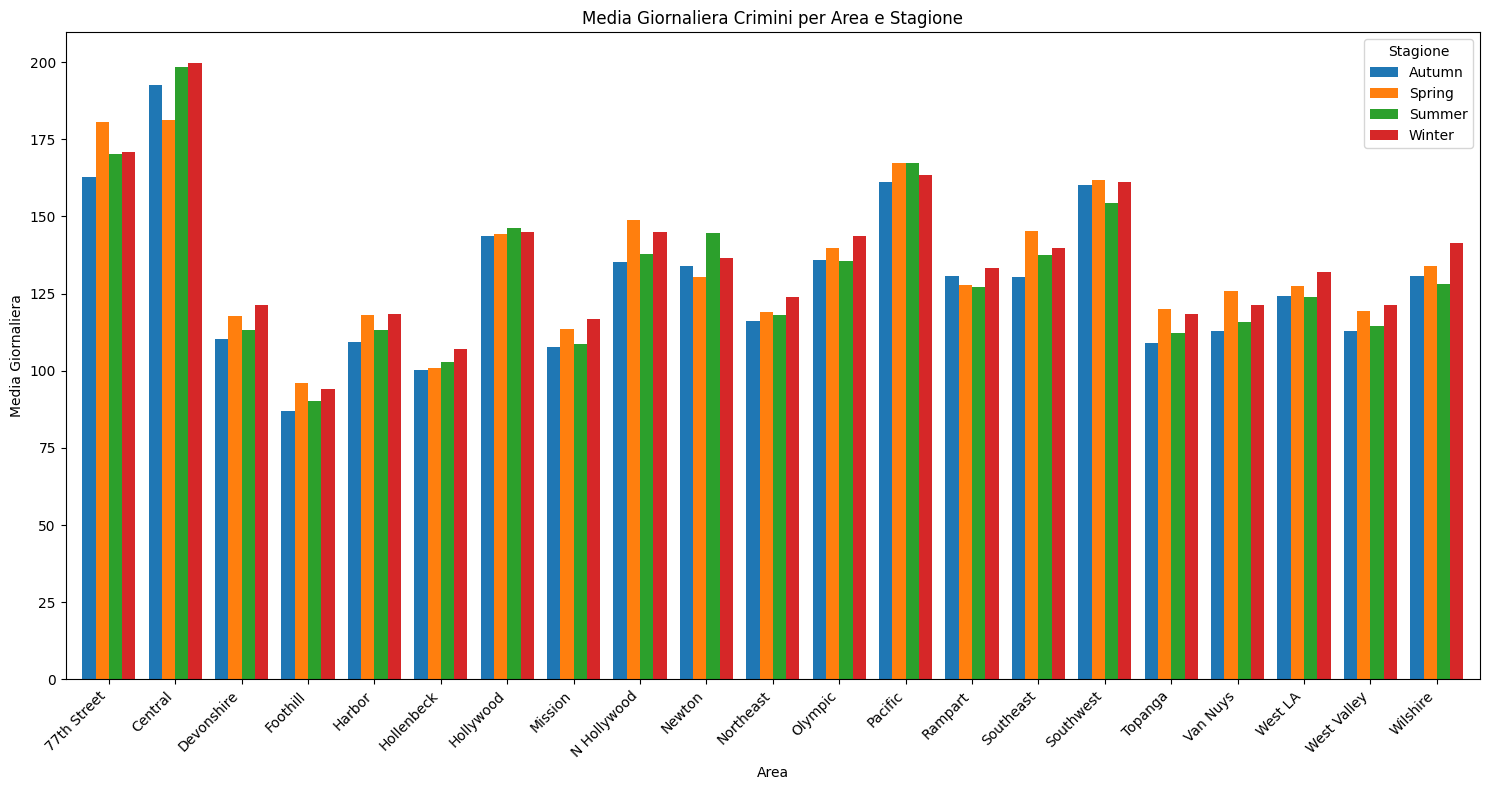

In [9]:
# 1. Numero medio giornaliero di crimini per area, raggruppato per stagione
seasonal_area_stats = df.groupby(['AREA NAME', 'Season']).size().reset_index(name='count')
# Normalizzazione per giorni (approssimata per semplicità, ideale sarebbe dividere per giorni effettivi nella stagione)
seasonal_area_stats['daily_avg'] = seasonal_area_stats['count'] / 90 # approx 3 mesi

# Pivot per plotting
pivot_df = seasonal_area_stats.pivot(index='AREA NAME', columns='Season', values='daily_avg')

# Plotting con Matplotlib
pivot_df.plot(kind='bar', figsize=(15, 8), width=0.8)
plt.title('Media Giornaliera Crimini per Area e Stagione')
plt.ylabel('Media Giornaliera')
plt.xlabel('Area')
plt.legend(title='Stagione')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

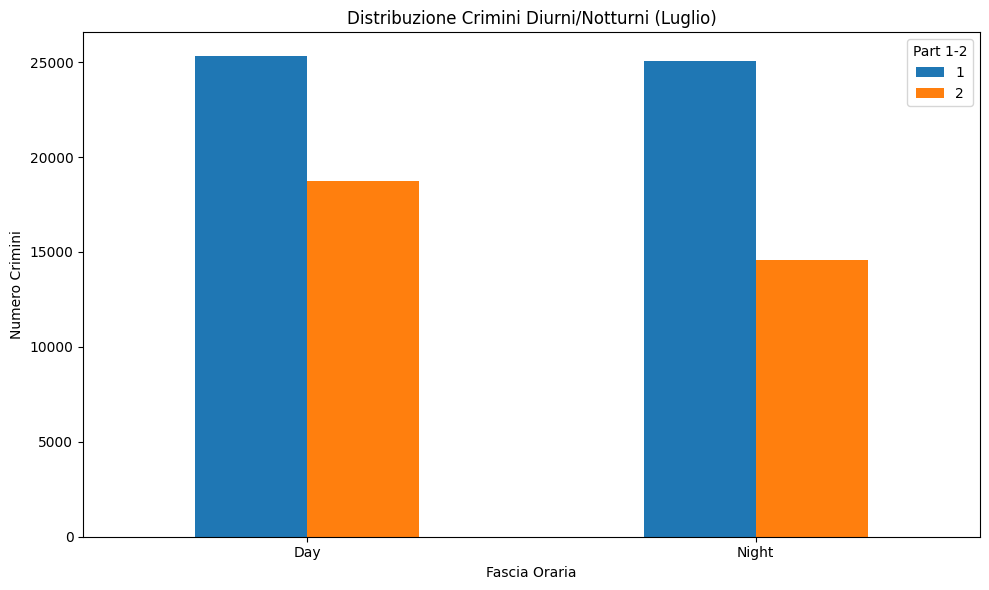

In [10]:
# 2. Distribuzione categorie crimine (Part 1-2) per fasce orarie (Mese a scelta: Luglio)
july_crimes = df[df['DATE OCC'].dt.month == 7].copy()

def get_time_slot(time_occ):
    # TIME OCC è int (es. 1300)
    hour = int(time_occ / 100)
    if 6 <= hour < 18:
        return "Day"
    else:
        return "Night"

july_crimes['Time_Slot'] = july_crimes['TIME OCC'].apply(get_time_slot)

time_slot_stats = july_crimes.groupby(['Time_Slot', 'Part 1-2']).size().reset_index(name='count')

# Pivot per plotting
pivot_df = time_slot_stats.pivot(index='Time_Slot', columns='Part 1-2', values='count')

# Plotting con Matplotlib
pivot_df.plot(kind='bar', figsize=(10, 6))
plt.title('Distribuzione Crimini Diurni/Notturni (Luglio)')
plt.ylabel('Numero Crimini')
plt.xlabel('Fascia Oraria')
plt.legend(title='Part 1-2')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# 3. Giornata con maggior numero di crimini violenti per area
# Assumiamo Part 1 come proxy per crimini violenti/gravi per questo esempio
violent_crimes = df[df['Part 1-2'] == 1]

daily_violent = violent_crimes.groupby(['AREA NAME', 'DATE OCC']).size().reset_index(name='count')
idx = daily_violent.groupby(['AREA NAME'])['count'].transform(max) == daily_violent['count']
peak_violent_days = daily_violent[idx].sort_values('count', ascending=False)

print("Giornate con picco di crimini violenti per area:")
peak_violent_days.head(10)

Giornate con picco di crimini violenti per area:


,AREA NAME,DATE OCC,count
36648,Wilshire,2020-05-30,263
1973,Central,2020-05-29,94
28682,Southwest,2023-08-06,90
31178,Van Nuys,2020-06-01,50
22909,Pacific,2022-10-11,45
11613,Hollywood,2021-10-30,44
21494,Olympic,2023-11-24,43
1410,77th Street,2023-11-11,42
16990,Newton,2021-07-25,42
19652,Northeast,2023-11-11,41


In [12]:
# 4. Età media vittime per categoria e anno
df['Year'] = df['DATE OCC'].dt.year
# Filtriamo età valide (>0)
valid_age = df[df['Vict Age'] > 0]

age_stats = valid_age.groupby(['Crm Cd Desc', 'Year'])['Vict Age'].mean().reset_index()
age_stats.head()

,Crm Cd Desc,Year,Vict Age
0,ARSON,2020,44.372654
1,ARSON,2021,47.012780
2,ARSON,2022,44.292929
3,ARSON,2023,44.597059
4,ARSON,2024,43.583333


## 3. Analisi Avanzata (Clustering)

Clustering incrementale sui pattern di criminalità.

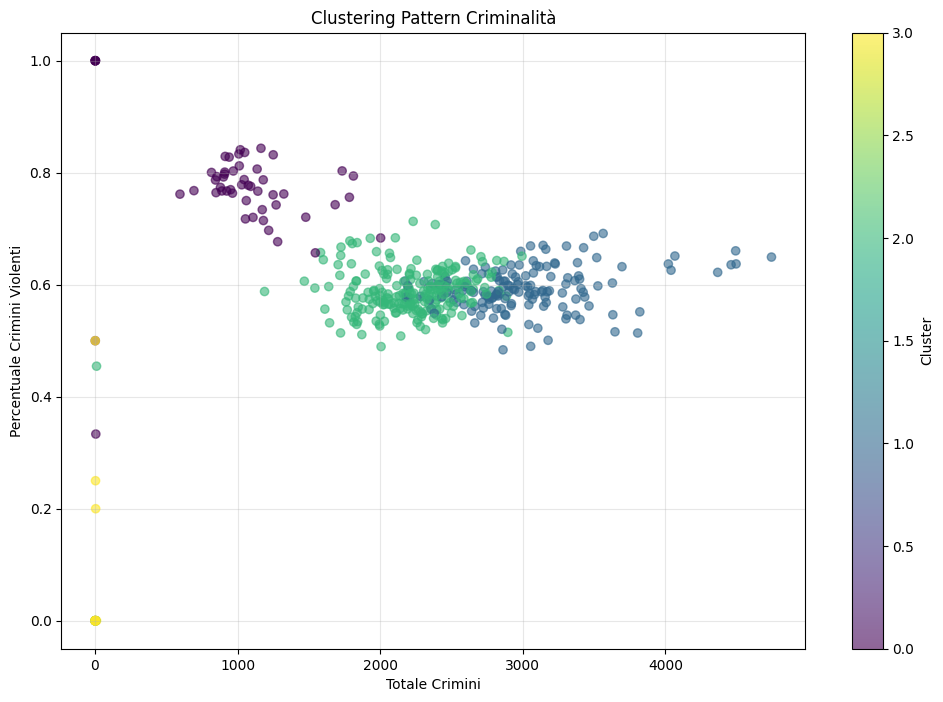

In [13]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

# Preparazione feature per clustering
# Aggregazione per Area, Stagione, Anno
df['Is_Night'] = df['TIME OCC'].apply(lambda x: 1 if (x < 600 or x >= 1800) else 0)
df['Is_Violent'] = df['Part 1-2'].apply(lambda x: 1 if x == 1 else 0)

features = df.groupby(['AREA NAME', 'Season', 'Year']).agg(
    total_crimes=('DR_NO', 'count'),
    weapon_pct=('Has_Weapon', 'mean'),
    night_pct=('Is_Night', 'mean'),
    violent_pct=('Is_Violent', 'mean')
).reset_index()

X = features[['total_crimes', 'weapon_pct', 'night_pct', 'violent_pct']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Clustering Incrementale
kmeans = MiniBatchKMeans(n_clusters=4, random_state=42, batch_size=256)
features['Cluster'] = kmeans.fit_predict(X_scaled)

# Visualizzazione risultati con Matplotlib
plt.figure(figsize=(12, 8))
scatter = plt.scatter(features['total_crimes'], features['violent_pct'], 
                     c=features['Cluster'], cmap='viridis', alpha=0.6)
plt.colorbar(scatter, label='Cluster')
plt.title('Clustering Pattern Criminalità')
plt.xlabel('Totale Crimini')
plt.ylabel('Percentuale Crimini Violenti')
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
# Analisi stabilità cluster 2020 vs 2025
cluster_changes = features[features['Year'].isin([2020, 2025])].pivot_table(
    index=['AREA NAME', 'Season'], 
    columns='Year', 
    values='Cluster'
).dropna()

cluster_changes['Changed'] = cluster_changes[2020] != cluster_changes[2025]
changes_count = cluster_changes['Changed'].sum()
total_comparisons = len(cluster_changes)

print(f"Aree/Stagioni che hanno cambiato cluster tra 2020 e 2025: {changes_count} su {total_comparisons}")

Aree/Stagioni che hanno cambiato cluster tra 2020 e 2025: 27 su 29
